# Quantum BiGAN — structured synthetic worlds

The original `GAN_01.ipynb` and stage-one `GAN_01_latent4.ipynb` are preserved.
Implementation is in `quantum_bigan.py`; this notebook validates stages in order
and runs a reproducible experiment in the existing DOUBT_QC environment.

The dataset is reproduced exactly from `I_JEPA_05.ipynb`, cell 2: grayscale
images of shape `(1,8,8)` with `image=a*x+b*y`, `a,b` in `[0.2,0.8)`.
Training has 256 images (seed 42); testing has 128 (seed 123). Intensities can
exceed one, so no clipping or per-image normalization is applied.

The latent prior is Uniform(-pi,pi)^4. The generator retains the stage-one
six-qubit SamplerQNN and 84 quantum weights, adding a learned pixel decoder.
It consumes measured probabilities as features, rather than sampling an image
from a bitstring. The encoder uses a learned 64-pixel-to-four-angle projection,
a four-qubit EstimatorQNN with 24 weights, and four Pauli-Z expectations scaled
by pi. Both QNNs retain TorchConnector with input gradients enabled.

The 20-unit classical discriminator receives 64 image pixels and four latents.
It scores `(x,E(x))` as real and `(G(z),z)` as generated. D minimizes balanced
BCE; G/E use the non-saturating objective with both labels flipped. No
reconstruction or factor supervision is added to adversarial training.

References: [original Qiskit qGAN tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/04_torch_qgan.html)
and [TorchConnector tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/05_torch_connector.html).

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import torch
from quantum_bigan import make_images_and_labels, verify_dataset_source

ROOT = Path.cwd()
assert (ROOT / 'quantum_bigan.py').is_file(), 'Open this notebook from DOUBT_QC'
print('Interpreter:', sys.executable)
print(json.dumps(verify_dataset_source(), indent=2))

Interpreter: C:\Users\giuse\.conda\envs\DOUBT_QC\python.exe
{
  "source": "I_JEPA_05.ipynb, cell 2",
  "exact_match": true,
  "splits": {
    "train": {
      "count": 256,
      "seed": 42,
      "image_sha256": "854dac4373279bfce9209ae2a323925fa066bf5c096bc6539d1bbe964b04ae9c",
      "label_sha256": "3ab4db9a7c002eaf0f534f39cf9cb8adb6ce2bc75a6cc963ce7ac8545943a36d"
    },
    "test": {
      "count": 128,
      "seed": 123,
      "image_sha256": "ecb42cb3ad0b1e11c7a213e2563b596262298e608cc67391212e9da1957c1dc2",
      "label_sha256": "bd736c311c24d2c4d871a82df85c2b041889e7844e1fbb9860b06bb238b5dda9"
    }
  }
}


In [2]:
train_images, train_labels = make_images_and_labels(256, 42)
test_images, test_labels = make_images_and_labels(128, 123)
print('Train/test shapes:', tuple(train_images.shape), tuple(test_images.shape))
print('Training intensity range:', train_images.min().item(), train_images.max().item())

Train/test shapes: (256, 1, 8, 8) (128, 1, 8, 8)
Training intensity range: 0.0 1.5442861318588257


## Validate each stage before training

Each check runs with this kernel's interpreter. Failure stops execution before
training. These checks also confirm that the original notebooks remain unchanged.

In [3]:
for script in ['validate_latent_generator.py', 'validate_quantum_encoder.py', 'validate_bigan_training.py']:
    completed = subprocess.run([sys.executable, str(ROOT / script)], cwd=ROOT,
                               capture_output=True, text=True)
    print(completed.stdout)
    if completed.stderr:
        print(completed.stderr)
    completed.check_returncode()

Fit in 17.07 sec
{
  "stage": 1,
  "status": "passed",
  "original_sha256": "34caa543d1d1b0c597fbc26302e7e6a09172befab4c2d934c85c5662f8326d63",
  "versions": {
    "qiskit": "2.3.1",
    "qiskit-machine-learning": "0.9.1",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.2",
    "scipy": "1.16.1"
  },
  "latent_dim": 4,
  "trainable_weights": 84,
  "output_shape": [
    2,
    64
  ],
  "latent_distribution_l1_difference": 0.9375,
  "checks": [
    "parameter separation",
    "single and batch forward",
    "normalized probabilities",
    "latent sensitivity",
    "input and weight gradients",
    "optimizer update",
    "two training epochs",
    "latent-marginal evaluation",
    "original unchanged"
  ],
  "generator_loss": [
    0.6070265769958496,
    0.6374545693397522
  ],
  "discriminator_loss": [
    0.6998146772384644,
    0.696328341960907
  ],
  "relative_entropy": [
    0.5906594062753409,
    0.6869961205132343
  ],
  "elapsed_seconds": 26.83493839998846
}



Earlier JEPA dataset exactly reproduced
{
  "stage": 2,
  "status": "passed",
  "dataset": {
    "source": "I_JEPA_05.ipynb, cell 2",
    "exact_match": true,
    "splits": {
      "train": {
        "count": 256,
        "seed": 42,
        "image_sha256": "854dac4373279bfce9209ae2a323925fa066bf5c096bc6539d1bbe964b04ae9c",
        "label_sha256": "3ab4db9a7c002eaf0f534f39cf9cb8adb6ce2bc75a6cc963ce7ac8545943a36d"
      },
      "test": {
        "count": 128,
        "seed": 123,
        "image_sha256": "ecb42cb3ad0b1e11c7a213e2563b596262298e608cc67391212e9da1957c1dc2",
        "label_sha256": "bd736c311c24d2c4d871a82df85c2b041889e7844e1fbb9860b06bb238b5dda9"
      }
    }
  },
  "encoder_qubits": 4,
  "quantum_weights": 24,
  "latent_shape": [
    2,
    4
  ],
  "checks": [
    "exact prior dataset reproduction",
    "image sensitivity",
    "finite outputs",
    "image, preprocessing and quantum gradients",
    "optimizer updates",
    "notebooks unchanged"
  ]
}



Discriminator update isolation passed
{
  "stage": 3,
  "status": "passed",
  "image_shape": [
    2,
    1,
    8,
    8
  ],
  "pair_input_size": 68,
  "discriminator_loss": 0.6585428714752197,
  "generator_encoder_loss": 0.7391968369483948,
  "gradient_norms": {
    "generator.quantum.weight": 0.02657201699912548,
    "generator.decoder.0.weight": 0.0815679058432579,
    "generator.decoder.0.bias": 0.006623163353651762,
    "generator.decoder.2.weight": 0.06392744183540344,
    "generator.decoder.2.bias": 0.015101184137165546,
    "encoder.image_to_angles.weight": 0.07383153587579727,
    "encoder.image_to_angles.bias": 0.020223744213581085,
    "encoder.quantum.weight": 0.007747529540210962
  },
  "checks": [
    "generated image shape/range",
    "latent sensitivity",
    "latent gradient",
    "real/fake pair logits",
    "D-only update",
    "G/E-only update",
    "finite losses"
  ]
}



## Development training run

Defaults use two epochs on a fixed 32-image subset of the training split, keeping
CPU validation practical. Evaluation uses all 128 test images. The linear factor
probe is fitted on all 256 training images only; factor labels never enter the
adversarial losses. Increase TRAIN_COUNT to 256 and EPOCHS for a full experiment.
This short run demonstrates execution and gradient flow, not convergence.
The generator uses 1024 shots and a fixed simulator seed for reproducibility.

In [4]:
EPOCHS = 2
TRAIN_COUNT = 32
BATCH_SIZE = 4
OUTPUT_DIR = ROOT / 'bigan_results'

command = [sys.executable, str(ROOT / 'run_quantum_bigan.py'),
           '--epochs', str(EPOCHS), '--train-count', str(TRAIN_COUNT),
           '--batch-size', str(BATCH_SIZE), '--output-dir', str(OUTPUT_DIR)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
completed.check_returncode()

Evaluating untrained baseline on original held-out split
Epoch 1/2, examples 4/32: D=0.65553, GE=0.74179
Epoch 1/2, examples 8/32: D=0.66025, GE=0.73497
Epoch 1/2, examples 12/32: D=0.66192, GE=0.73155
Epoch 1/2, examples 16/32: D=0.65221, GE=0.74257
Epoch 1/2, examples 20/32: D=0.64304, GE=0.75328
Epoch 1/2, examples 24/32: D=0.63770, GE=0.75972
Epoch 1/2, examples 28/32: D=0.66903, GE=0.72399
Epoch 1/2, examples 32/32: D=0.63921, GE=0.75844
Epoch 2/2, examples 4/32: D=0.64188, GE=0.75590
Epoch 2/2, examples 8/32: D=0.65030, GE=0.74472
Epoch 2/2, examples 12/32: D=0.62344, GE=0.77692
Epoch 2/2, examples 16/32: D=0.68382, GE=0.71433
Epoch 2/2, examples 20/32: D=0.64669, GE=0.74841
Epoch 2/2, examples 24/32: D=0.64582, GE=0.75014
Epoch 2/2, examples 28/32: D=0.69497, GE=0.70114
Epoch 2/2, examples 32/32: D=0.67762, GE=0.72092
Evaluating trained model on all 128 held-out images
{
  "initial": {
    "encoder_factor_probe": {
      "test_mse": 0.00020570624940820896,
      "test_r2_a_b": [

{
  "initial": {
    "encoder_factor_probe": {
      "test_mse": 0.00020570624940820896,
      "test_r2_a_b": [
        0.9935842079462099,
        0.991965291018601
      ]
    },
    "raw_pixel_factor_probe": {
      "test_mse": 4.942417719783744e-31,
      "test_r2_a_b": [
        1.0,
        1.0
      ]
    },
    "constant_factor_baseline_mse": 0.028961192816495895,
    "reconstruction_mse": 0.17119374871253967,
    "mean_image_baseline_mse": 0.01908898912370205,
    "image_rbf_mmd_squared": 1.255370353590086,
    "mmd_bandwidth_from_train": 1.3000332871968756,
    "generated_pixel_variance": 0.007418568711727858,
    "real_pixel_variance": 0.018756981939077377,
    "generated_plane_residual_mse": 0.12528853118419647,
    "generated_factor_mean": [
      0.6425073146820068,
      0.649965226650238
    ],
    "real_factor_mean": [
      0.5143521428108215,
      0.48802608251571655
    ],
    "generated_factor_std": [
      0.023992422968149185,
      0.02574249729514122
    ],
  

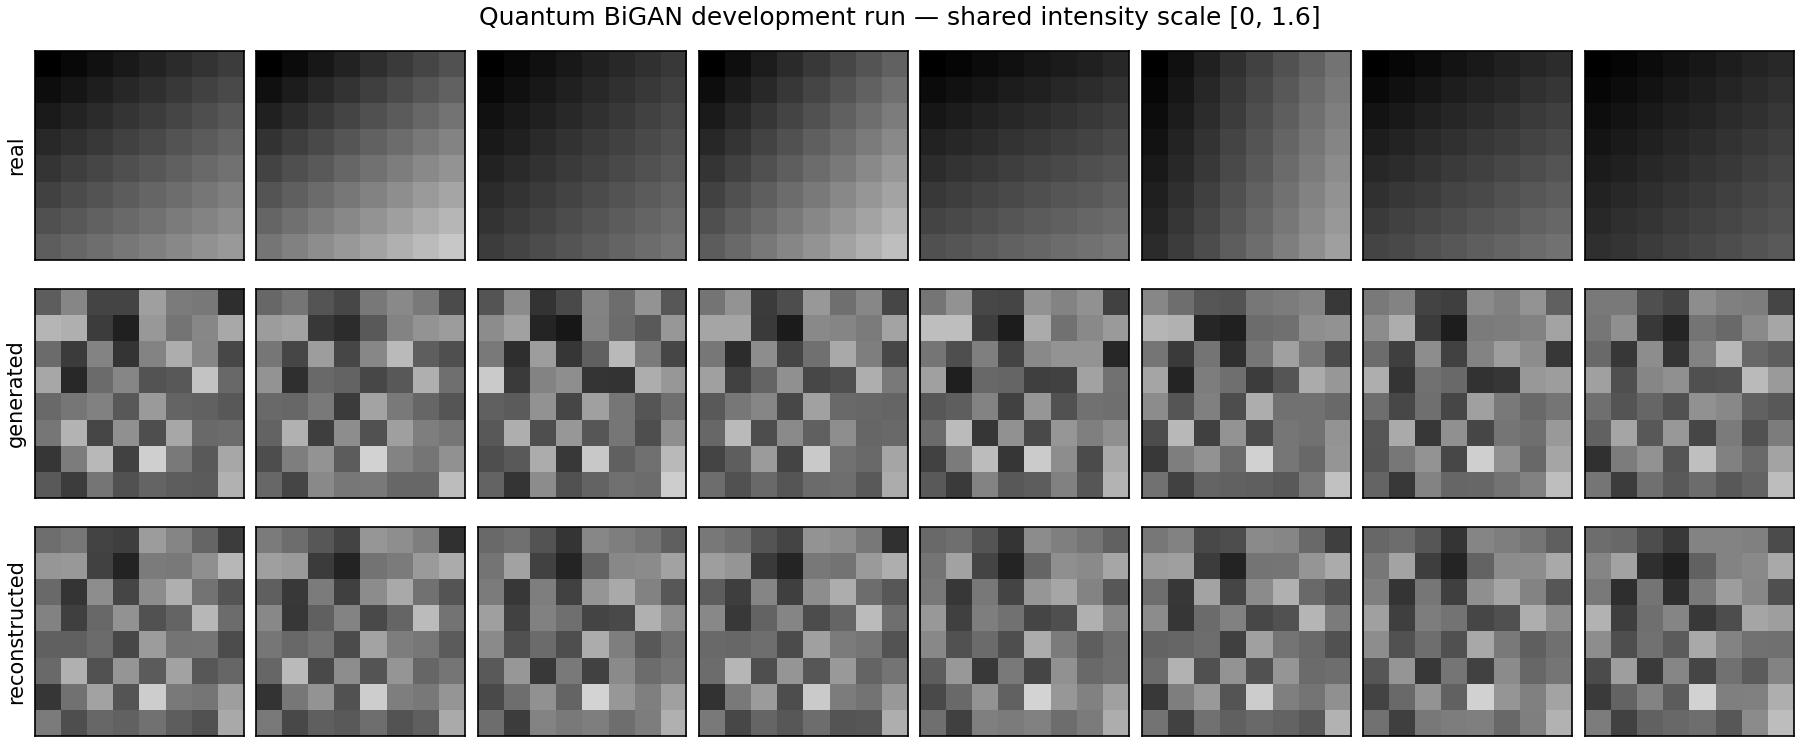

In [5]:
report = json.loads((OUTPUT_DIR / 'evaluation.json').read_text())
print(json.dumps({'initial': report['initial'], 'final': report['final'],
                  'history': report['history']}, indent=2))
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / 'examples.png')))

## Reading the evaluation

The encoder probe predicts the known `(a,b)` factors; compare held-out MSE and
R² with the untrained encoder, raw pixels, and training-mean labels. Raw pixels
already contain these factors linearly, so this dataset cannot by itself
demonstrate a quantum advantage.

Image RBF MMD² compares generated and held-out image distributions using a
bandwidth chosen from training data only. Reconstruction MSE is diagnostic:
the BiGAN objective does not directly optimize it. Pixel variance and the
residual from the known planar image structure help detect collapse and
off-manifold outputs. Generated images are independent samples and are not
paired with the real images displayed above them. Reconstructions correspond
to those real images. Finite-shot generator probabilities introduce simulation
noise; repeat longer experiments across seeds before drawing quality conclusions.

Results and weights are saved separately under `bigan_results`, leaving the
original qGAN and JEPA artifacts intact.